# Molecular Docking + MD — Anticancer: 5EHR + SHP099

Real confirmed-binder question: SHP099 (PubChem CID 118238298) IS the real co-crystallized allosteric
inhibitor in 5EHR (SHP2/PTPN11) — the one pair in this project with a true ground-truth pose, so this
notebook includes a real redocking-RMSD validation step before MD (PROJECT_NARRATIVE.md Section 5).

This notebook follows the project's standard discipline: ~80-90% of code cells are blank (`____`) for you
to fill in, with a concrete real-code hint given either inline (trailing comment) or in a preceding
`# hint:` block — never a vague description. GROMACS is installed via a real, verified-to-exist prebuilt
CUDA binary from conda-forge (`mamba install -c conda-forge -c bioconda "gromacs=*=*cuda*"`), which is
faster and more network-reliable on Kaggle than compiling GROMACS from source.


In [1]:
import os

# directories only -- every package below is installed right before the cell that first needs it,
# not all up front. This way if Kaggle gives you a fresh kernel partway through, you only need to
# re-run the installs for the step you're actually on, not guess which one silently vanished.
for d in ["data/receptors", "data/ligands", "data/pockets", "results/docking"]:
    os.makedirs(d, exist_ok=True)
print("directories ready")


directories ready


## Step 0 — Directories only

Packages are installed just-in-time, immediately before the cell that first needs them (Step 2:
`openbabel-wheel`; Step 3: `fpocket`; Step 4: `rdkit`/`meeko`/`gemmi`; Step 5: `vina`; Step 6:
`gromacs`/`pdbfixer`/`openmm`/`acpype`; the visualization step: `py3Dmol`) -- so a fresh Kaggle
kernel only ever costs you a re-install of what the step you're actually on needs, not a guess about
what silently disappeared from a giant Step 0.

## Step 1 — Fetch the real receptor structure (5EHR)

**WHAT:** download the real PDB coordinate file for this target, live from RCSB.
**WHY (biology):** anticancer. This is a real, experimentally-solved X-ray structure (see
`PROJECT_NARRATIVE.md` Section 3a for how it was actually generated).
**HOW:** RCSB's file-download endpoint follows a fixed real pattern:
`https://files.rcsb.org/download/{PDB_ID}.pdb` — look up `requests.get` + `.text`, write to
`data/receptors/5EHR.pdb`.

In [2]:
import requests

PDB_ID = "5EHR"

url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"
resp = requests.get(url)
with open(f"data/receptors/{PDB_ID}.pdb", "w") as f:
    f.write(resp.text)
print(PDB_ID, "saved,", len(resp.text), "chars")


5EHR saved, 747144 chars


## Step 2 — Prepare the receptor (strip waters, resolve alternate conformations, add hydrogens)

**WHAT:** clean the raw crystal PDB into a docking-ready, geometrically well-behaved receptor.
**WHY (biology):** crystallographic waters and buffer/cryoprotectant molecules are real experimental
artifacts of crystallization, not part of the biological binding event, and must be removed. Separately,
many real X-ray structures (6ML0 included — confirmed live: it has 26 real altLoc-B atoms) resolve some
sidechains into two real **alternate conformations** ("altLoc" A/B records at near-identical coordinates,
representing genuine crystallographic ambiguity about which rotamer is "真" at that position). Downstream
tools that build 3D geometry from the atom set (fpocket's internal Voronoi/qhull step, in particular) can
crash on these near-duplicate points if both conformations are kept — so real structural-biology practice is
to keep only ONE conformation (conventionally altLoc "A", or blank where there's no alternate) before any
geometric computation.
**WHY (chemistry):** hydrogens are usually invisible at X-ray resolution and must be added back
computationally, at a real, chosen protonation state (physiological pH ~7.4).
**HOW:** filter by residue name AND by the real PDB altLoc column (column 17, 0-indexed `line[16]`), then
Open Babel: `obabel input.pdb -O output.pdbqt -xr --partialcharge gasteiger` (`-xr` = rigid receptor
output).

In [3]:
import sys
!{sys.executable} -m pip install -q openbabel-wheel

WATER_BUFFER_RESNAMES = {"HOH", "GOL", "PEG", "EDO", "SO4", "PO4", "MES", "ACT", "NA", "CL", "DMS"}
# GIVEN -- real, standard crystallographic water/buffer/cryoprotectant residue codes (not exhaustive, but
# covers the common ones).

raw_path = f"data/receptors/{PDB_ID}.pdb"
clean_path = f"data/receptors/{PDB_ID}_clean.pdb"
receptor_pdbqt = f"data/receptors/{PDB_ID}_receptor.pdbqt"

with open(raw_path) as f:
    lines = f.readlines()
kept = []
for ln in lines:
    if ln.startswith(("ATOM", "HETATM")):
        if ln[16] not in (" ", "A"):
            continue
        if ln.startswith("HETATM") and ln[17:20].strip() in WATER_BUFFER_RESNAMES:
            continue
    kept.append(ln)
with open(clean_path, "w") as f:
    f.writelines(kept)

!obabel {clean_path} -O {receptor_pdbqt} -xr --partialcharge gasteiger

print("receptor prepared")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 94.9 MB/s eta 0:00:00:00:0100:01
*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  columns 7-11 should contain the serial number of an atom.
  No atom was found with this serial number.
  THIS CONECT RECORD WILL BE IGNORED.

*** Open Babel Warning  in parseConectRecord
  Problems reading a CONECT record.
  According to the PDB specification,
  

## Step 3 — Detect the real binding site (fpocket) — NOT blind docking

**WHAT:** run fpocket on the prepared (altLoc-resolved, water-stripped) receptor and choose the real pocket
to dock into.
**WHY (biology):** a binding pocket is a real, druggable cavity — fpocket finds clusters of geometric probe
spheres (alpha-spheres) fitting concave surface regions, ranked by a druggability score. Here, this target has a real co-crystallized ligand in the original PDB file, so you can directly check whether the top-ranked pocket's centroid overlaps the real known ligand position — a real validation of the pocket-detection step itself.
**HOW:** `!fpocket -f data/receptors/{PDB_ID}_clean.pdb` writes a `*_out/` directory with ranked pocket PDB
files (named `pocket1_atm.pdb`, `pocket2_atm.pdb`, ... by druggability rank); parse the chosen pocket's
atoms, compute centroid + a padded bounding box for the Vina search box.
**If fpocket errors with a `qhull`/`QH60xx` message:** that's a real sign Step 2's altLoc filtering didn't
fully resolve a degenerate geometry — re-check `clean_path` for any remaining duplicate-position atoms
before re-running, rather than retrying blindly.

In [4]:
import os, numpy as np, glob

# fpocket: bioconda prebuilt binary, NOT compiled from source (a from-source build was confirmed
# miscompiled in this environment on notebook 01 -- its crash survived 3 independent data-side fixes,
# which is what proved it was a build problem, not a data problem)
if not os.path.exists("/usr/local/miniforge3/bin/mamba"):
    print("installing miniforge...")
    !wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O /tmp/miniforge.sh
    !bash /tmp/miniforge.sh -b -p /usr/local/miniforge3
    print("miniforge done")

os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

print("installing fpocket (bioconda) -- real-time output below, takes a few minutes, let it run...")
!mamba install -y -c bioconda -c conda-forge fpocket
!fpocket -h | head -3

!fpocket -f data/receptors/{PDB_ID}_clean.pdb

pocket_files = sorted(glob.glob(f"data/receptors/{PDB_ID}_clean_out/pockets/pocket*_atm.pdb"))
top_pocket_path = pocket_files[0]

coords = []
with open(top_pocket_path) as f:
    for line in f:
        if line.startswith(("ATOM", "HETATM")):
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
coords = np.array(coords)

center = coords.mean(axis=0)
box_min, box_max = coords.min(axis=0), coords.max(axis=0)
padding = 5.0
size = (box_max - box_min) + 2 * padding

print("pocket center:", center, "size:", size)


installing miniforge...
PREFIX=/usr/local/miniforge3
Unpacking bootstrapper...
Unpacking payload...
Extracting ca-certificates-2026.7.22-hbd8a1cb_0.conda
Extracting libgomp-16.2.0-he0feb66_4.conda
Extracting libzlib-1.3.2-h25fd6f3_3.conda
Extracting nlohmann_json-abi-3.12.0-h0f90c79_2.conda
Extracting pybind11-abi-11-hc364b38_1.conda
Extracting python_abi-3.14-9_cp314.conda
Extracting tzdata-2026c-h151e31d_0.conda
Extracting _openmp_mutex-4.5-20_gnu.conda
Extracting zstd-1.5.7-hb78ec9c_7.conda
Extracting ld_impl_linux-64-2.46.1-default_hbd61a6d_102.conda
Extracting libgcc-16.2.0-ha9f2e26_4.conda
Extracting bzip2-1.0.8-hda65f42_10.conda
Extracting c-ares-1.34.8-hebe6cf0_2.conda
Extracting keyutils-1.6.3-h7cc23a3_1.conda
Extracting libev-4.33-h280c20c_3.conda
Extracting libexpat-2.8.1-hecca717_1.conda
Extracting libffi-3.7.0-h81df57d_1.conda
Extracting libiconv-1.18-h0cb94f2_3.conda
Extracting liblzma-5.8.3-hb03c661_1.conda
Extracting libmpdec-4.0.0-hb03c661_2.conda
Extracting libstdcxx-

## Step 4 — Fetch + prepare the real ligand (SHP099, CID 118238298)

**WHAT:** download the ligand's real 3D structure by PubChem CID, then convert to a Vina-ready PDBQT.
**WHY:** 
**HOW:** PubChem PUG-REST 3D SDF endpoint:
`https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{CID}/SDF?record_type=3d`. Then RDKit
(`Chem.MolFromMolFile`) + Meeko's `MoleculePreparation`/`PDBQTWriterLegacy` for PDBQT conversion (real
partial charges + rotatable-bond definitions Vina needs).

In [5]:
CID = "118238298"

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{CID}/SDF?record_type=3d"
resp = requests.get(url)
sdf_path = f"data/ligands/{CID}.sdf"
with open(sdf_path, "w") as f:
    f.write(resp.text)
print(CID, "saved")


118238298 saved


In [6]:
import sys
!{sys.executable} -m pip install -q rdkit meeko gemmi

from rdkit import Chem
from meeko import MoleculePreparation, PDBQTWriterLegacy

mol = Chem.MolFromMolFile(sdf_path, removeHs=False)

preparator = MoleculePreparation()
mol_setups = preparator.prepare(mol)
pdbqt_string, ok, err = PDBQTWriterLegacy.write_string(mol_setups[0])

ligand_pdbqt = f"data/ligands/{CID}.pdbqt"
with open(ligand_pdbqt, "w") as f:
    f.write(pdbqt_string)
print(CID, "-> PDBQT ready")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 66.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 73.4 MB/s eta 0:00:00:00:01
118238298 -> PDBQT ready


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Step 5 — Dock (AutoDock Vina, targeted box)

**WHAT:** dock this ligand into the real detected pocket from Step 3 — never the whole protein.
**WHY:** the actual structure-based prediction step: for each sampled pose, Vina's scoring function
estimates a real binding affinity (kcal/mol; more negative = predicted tighter binding).
**HOW:** the `vina` package's `Vina` class: `set_receptor`, `set_ligand_from_file`,
`compute_vina_maps(center=..., box_size=...)`, `dock(exhaustiveness=..., n_poses=...)`, `write_poses(...)`.

In [7]:
import sys
print("installing vina + its build deps (swig, boost)...")
!apt-get update -qq && apt-get install -y -qq swig libboost-all-dev > /dev/null
!{sys.executable} -m pip install -q vina

from vina import Vina

v = Vina(sf_name="vina")

v.set_receptor(receptor_pdbqt)
v.set_ligand_from_file(ligand_pdbqt)
v.compute_vina_maps(center=list(center), box_size=list(size))
v.dock(exhaustiveness=16, n_poses=9)

pose_path = f"results/docking/{PDB_ID}_{CID}_poses.pdbqt"
v.write_poses(pose_path, n_poses=9, overwrite=True)

best_affinity = v.energies(n_poses=1)[0][0]
print(PDB_ID, CID, "->", best_affinity, "kcal/mol")


installing vina + its build deps (swig, boost)...


/usr/lib/python3.13/pty.py:95: DeprecationWarning: This process (pid=49) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Computing Vina grid ... done.
Performing docking (random seed: -297302561) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
5EHR 118238298 -> -6.121 kcal/mol


## Redocking self-validation (real, atom-order-safe RMSD)

**WHAT:** compare your docked pose to the real deposited SHP099 coordinates in the original 5EHR PDB file --
the one pair in this project where the screened ligand IS the real crystallographic ligand.
**WHY:** the direct, real test of whether your whole pipeline (receptor prep + pocket detection + docking)
actually works -- low RMSD (conventionally < 2 A) means Vina recovered the true binding mode.
**IMPORTANT (a real, easy-to-miss mistake):** the real crystal ligand's atoms and your docked pose's atoms
are NOT guaranteed to be in the same order -- they came from two completely different pipelines (the PDB's
own deposited atom order vs. PubChem -> RDKit -> Meeko). Subtracting the two coordinate arrays directly,
atom-by-atom, would silently give a meaningless number, or crash outright on an atom-count mismatch. The
real fix: use RDKit's `rdMolAlign.GetBestRMS`, which matches atoms by molecular graph (handling both
reordering and chemical symmetry) before computing RMSD -- never subtract raw coordinate arrays directly
unless you have independently verified identical atom order.
**HOW:** build an RDKit Mol for the real crystal pose from `5EHR.pdb`'s own SHP099 HETATM lines
(`Chem.MolFromPDBBlock`, which perceives bonds from atomic distances); convert your docked pose's PDBQT
back to a plain PDB (Open Babel, first model only) and load that the same way; then
`rdMolAlign.GetBestRMS(probe, ref)`. If `MolFromPDBBlock` fails to perceive correct bonds for a molecule
this size (a known real limitation of distance-based bond perception on larger, druglike ligands), the
documented fallback is `Chem.MolFromPDBBlock(ref_pdb_block, sanitize=False)` plus
`AllChem.AssignBondOrdersFromTemplate` against the already-correct-bonded PubChem SDF mol from Step 4.

In [13]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign
from collections import Counter

hetatm_resnames = Counter()
with open("data/receptors/5EHR.pdb") as f:
    for line in f:
        if line.startswith("HETATM"):
            hetatm_resnames[line[17:20].strip()] += 1
candidate_resnames = {name: n for name, n in hetatm_resnames.items() if name not in WATER_BUFFER_RESNAMES}
SHP099_RESNAME = max(candidate_resnames, key=candidate_resnames.get)
print("SHP099 residue code (discovered live):", SHP099_RESNAME)

with open("data/receptors/5EHR.pdb") as f:
    shp099_lines = [l for l in f if l.startswith("HETATM") and l[17:20].strip() == SHP099_RESNAME]
ref_pdb_block = "".join(shp099_lines) + "END\n"

# RDKit can't infer correct bond orders from a bare crystallographic HETATM block (real PDB files carry
# no CONECT records for most ligands) -- assign the real bond orders from SHP099's known structure
# (PubChem CID 118238298, SMILES verified live) onto the real crystal coordinates
raw_ref_mol = Chem.MolFromPDBBlock(ref_pdb_block, sanitize=False, removeHs=False)
raw_ref_mol = Chem.RemoveHs(raw_ref_mol, sanitize=False)
shp099_template = Chem.MolFromSmiles("CC1(CCN(CC1)C2=CN=C(C(=N2)N)C3=C(C(=CC=C3)Cl)Cl)N")
ref_mol = AllChem.AssignBondOrdersFromTemplate(shp099_template, raw_ref_mol)

!obabel {pose_path} -O ligand.pdb -f 1 -l 1 
probe_mol = Chem.MolFromPDBFile("results/top_pose.pdb", removeHs=True)

redocking_rmsd = rdMolAlign.GetBestRMS(probe_mol, ref_mol)

print(f"5EHR + SHP099 redocking RMSD: {redocking_rmsd:.2f} Angstrom")
print("Under ~2 A is conventionally a successful redocking; report honestly either way.")

[RDKit] WARNING:[08:29:39] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:


SHP099 residue code (discovered live): 5OD
1 molecule converted
5EHR + SHP099 redocking RMSD: 0.60 Angstrom
Under ~2 A is conventionally a successful redocking; report honestly either way.


## Step 6 — GROMACS: build topologies (CONFIRMED-WORKING version, folded back from notebook 01)

**WHAT:** real molecular-mechanics topology files for the protein (amber99sb-ildn + TIP3P) and the
docked ligand (GAFF/AM1-BCC via ACPYPE).
**WHY:** MD needs a real force field defining every bonded/non-bonded interaction so forces can be
computed at every timestep (PROJECT_NARRATIVE.md Section 4).
**Confirmed live, folded back as GIVEN:** CHARMM36 is not bundled with this conda-forge GROMACS build
(switched to amber99sb-ildn); this structure's crystal coordinates may be missing heavy atoms on
flexible sidechains, which `pdb2gmx` cannot add on its own (PDBFixer added first); ACPYPE's real output
directory/file names must be discovered via `glob`, not assumed.

In [15]:
import os
# GROMACS: bioconda/conda-forge CUDA build (reuses the miniforge env bootstrapped in Step 3)
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]
print("installing GROMACS (bioconda, CUDA) -- a few minutes, real-time output below...")
!mamba install -y -c conda-forge -c bioconda "gromacs=*=*cuda*"
!gmx --version 2>&1 | grep -i -E "GPU|CUDA|VERSION"

print("installing pdbfixer, openmm, acpype...")
import sys
!{sys.executable} -m pip install -q pdbfixer openmm acpype

import os, sys, glob

# defensive -- re-add in case this is a fresh kernel since Step 0 ran
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# split the receptor and top docked pose into plain PDBs GROMACS/ACPYPE can read -- these are two
# SEPARATE real molecules (protein-only, ligand-only); the merge into one system happens in the next cell
# strip any real native ligand / hetero groups before building the protein-only input -- pdb2gmx must
# only ever see standard protein residues; a real native ligand (confirmed live: broke pdb2gmx on 5T2P
# with "Residue 'K89' not found in residue topology database") is not part of this notebook's MD
# system -- only the SCREENED ligand is, merged back in separately at Step 6b.
with open(clean_path) as f:
    protein_only_lines = [l for l in f if l.startswith(("ATOM", "TER", "END"))]
with open("protein_only.pdb", "w") as f:
    f.writelines(protein_only_lines)
!obabel protein_only.pdb -O protein.pdb
!obabel {pose_path} -O ligand.pdb -f 1 -l 1 -h

# PDBFixer: real X-ray structures commonly have missing heavy atoms on flexible/disordered sidechains
# (confirmed live on notebook 01: 6ML0's Lys225 was missing its CG atom) -- pdb2gmx can add hydrogens
# but not missing heavy atoms, so this has to run first
from pdbfixer import PDBFixer
from openmm.app import PDBFile

fixer = PDBFixer(filename="protein.pdb")
fixer.findMissingResidues()
fixer.findMissingAtoms()
fixer.addMissingAtoms()
fixer.addMissingHydrogens(7.0)
with open("protein_fixed.pdb", "w") as f:
    PDBFile.writeFile(fixer.topology, fixer.positions, f)
print("protein_fixed.pdb written, missing heavy atoms rebuilt")

# pdb2gmx with amber99sb-ildn -- CHARMM36 is NOT bundled with this conda-forge GROMACS build (confirmed
# live on notebook 01: it's historically distributed separately); amber99sb-ildn is bundled and equally
# standard for protein-ligand MD
!gmx pdb2gmx -f protein_fixed.pdb -o protein_processed.gro -water tip3p -ff amber99sb-ildn -ignh

# ACPYPE -- GAFF/AM1-BCC ligand topology. This genuinely takes several minutes (antechamber + sqm charge
# calculation); it is NOT stuck, Jupyter just buffers subprocess output until it finishes.
from rdkit import Chem
from rdkit.Chem import AllChem

# Reuse the real SHP099 template built earlier for the redocking RMSD check, instead of letting
# OpenBabel guess bonds on a ligand that's missing most of its hydrogens (confirmed: PDBQT strips
# nonpolar H's, leaving only 27 of the real ~42 atoms -- that's what caused the odd electron count)
!obabel {pose_path} -O ligand_heavy.pdb -f 1 -l 1

raw_pose_mol = Chem.MolFromPDBFile("ligand_heavy.pdb", removeHs=True, sanitize=False)
pose_mol = AllChem.AssignBondOrdersFromTemplate(shp099_template, raw_pose_mol)

ligand_net_charge = Chem.GetFormalCharge(pose_mol)
print("ligand net charge (from template-corrected bonds):", ligand_net_charge)

pose_mol_h = Chem.AddHs(pose_mol, addCoords=True)
print("ligand atom count after correct hydrogen addition:", pose_mol_h.GetNumAtoms())

Chem.MolToPDBFile(pose_mol_h, "ligand.pdb")

!acpype -i ligand.pdb -c bcc -n {ligand_net_charge} < /dev/null

# find ACPYPE's real output live (glob-based, not a hardcoded assumed directory name)
acpype_dirs = glob.glob("*.acpype")
assert acpype_dirs, "No *.acpype output directory found -- re-check the acpype command's own printed output above"
acpype_dir = acpype_dirs[0]
ligand_gro = glob.glob(f"{acpype_dir}/*_GMX.gro")[0]
ligand_itp = glob.glob(f"{acpype_dir}/*_GMX.itp")[0]
print("ligand_gro:", ligand_gro, "| ligand_itp:", ligand_itp)

# read the real ligand residue name directly from the ITP's own [ moleculetype ] entry
LIGAND_RESNAME = None
with open(ligand_itp) as f:
    lines = f.readlines()
for i, line in enumerate(lines):
    if "[ moleculetype ]" in line:
        for next_line in lines[i+1:]:
            cl = next_line.strip()
            if cl and not cl.startswith(";"):
                LIGAND_RESNAME = cl.split()[0]
                break
        break
assert LIGAND_RESNAME, "Could not read ligand residue name from ITP file"
print("LIGAND_RESNAME:", LIGAND_RESNAME)


installing GROMACS (bioconda, CUDA) -- a few minutes, real-time output below...
conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
bioconda/linux-64                                           Using cache
[+] 0.0s

Pinned packages:

  - python=3.14


Transaction

  Prefix: /usr/local/miniforge3

  All requested packages already installed


Transaction starting

Transaction finished

  gmx --version
GROMACS version:     2026.3-conda_forge
MPI version:         built in
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
Colvars support:     enabled (version 2025-10-13)
CUDA compiler:       /usr/local/miniforge3/bin/nvcc (NVIDIA 12.9.86)
CUDA compiler flags:  -O3 -DNDEBUG -use_fast_math -static-global-template-stub=false -Xptxas=-warn-double-usage -Xptxas=-Werror -diag-suppress=177 -use_fast_m

[RDKit] WARNING:[08:36:19] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:


ligand net charge (from template-corrected bonds): 0
ligand atom count after correct hydrogen addition: 42
| ACPYPE: AnteChamber PYthon Parser interfacE v. 2026.10.8 (c) 2026 AWSdS |
==> ... charge set to 0
==> ... converting pdb input file to mol2 input file
==> * Babel OK *
==> Executing Antechamber...
==> * Antechamber OK *
==> * Parmchk OK *
==> Executing Tleap...
==> * Tleap OK *
==> Removing temporary files...
==> Using OpenBabel v.3.1.0

==> Writing NEW PDB file

==> Writing CNS/XPLOR files

==> Writing GROMACS files

==> Disambiguating lower and uppercase atomtypes in GMX top file, even if identical.

==> Writing GMX dihedrals for GMX 4.5 and higher.

==> Writing CHARMM files

==> Writing pickle file ligand.pkl
==> Removing temporary files...
Total time of execution: 1m 12s
ligand_gro: ligand.acpype/ligand_GMX.gro | ligand_itp: ligand.acpype/ligand_GMX.itp
LIGAND_RESNAME: ligand


## Step 6b — Combine protein + ligand into one system (CONFIRMED-WORKING version)

**WHY:** if you solvate/minimize/run MD on only the protein's own `protein_processed.gro`, the ligand
is never actually present in the simulation -- the whole point of this notebook (does the docked pose
hold up under real dynamics) would silently not be tested.
**Confirmed live, folded back as GIVEN:** the atomtypes/moleculetype split below is required --
ACPYPE bundles both directives in one `.itp` file, and including it as-is right before `[ system ]`
breaks GROMACS's global ordering rule once the protein's own `[ moleculetype ]` has already been
declared earlier in the include hierarchy.

In [16]:
# combine coordinates into complex.gro -- reuses ligand_gro/ligand_itp/LIGAND_RESNAME from Step 6 above
with open("protein_processed.gro") as f:
    protein_lines = f.readlines()
with open(ligand_gro) as f:
    ligand_lines = f.readlines()

protein_atom_lines = protein_lines[2:-1]
ligand_atom_lines = ligand_lines[2:-1]
total_atoms = len(protein_atom_lines) + len(ligand_atom_lines)

combined = [protein_lines[0], f" {total_atoms}\n"] + protein_atom_lines + ligand_atom_lines + [protein_lines[-1]]
with open("complex.gro", "w") as f:
    f.writelines(combined)
print(f"complex.gro written with {total_atoms} total atoms")

# split ligand_GMX.itp at [ moleculetype ] -- atomtypes block vs moleculetype-onward block. GROMACS's
# grompp requires every [ atomtypes ] block to appear before any [ moleculetype ] block anywhere in the
# full include hierarchy -- ACPYPE bundles both in one file, which breaks this rule once included after
# the protein's own moleculetype (confirmed live on notebook 01: "Invalid order for directive atomtypes").
with open(ligand_itp) as f:
    itp_lines = f.readlines()
split_idx = next(i for i, l in enumerate(itp_lines) if l.strip().startswith("[ moleculetype ]"))
atomtypes_lines = itp_lines[:split_idx]
moleculetype_lines = itp_lines[split_idx:]

ligand_atomtypes_itp = "ligand_atomtypes.itp"
ligand_moltype_itp = "ligand_moleculetype.itp"
with open(ligand_atomtypes_itp, "w") as f:
    f.writelines(atomtypes_lines)
with open(ligand_moltype_itp, "w") as f:
    f.writelines(moleculetype_lines)

with open("topol.top") as f:
    top_lines = f.readlines()
top_text = "".join(top_lines)

# idempotency guard -- if this cell gets accidentally re-run, don't insert the ligand's #include lines
# a second time (that's exactly what causes a real "moleculetype ligand is redefined" error, confirmed
# live). Only insert when the ligand include is not already present.
if ligand_atomtypes_itp not in top_text:
    ff_include_idx = next(i for i, l in enumerate(top_lines)
                           if l.strip().startswith("#include") and ".ff/forcefield.itp" in l)
    top_lines.insert(ff_include_idx + 1, f'#include "{ligand_atomtypes_itp}"\n')

    insert_at = next(i for i, l in enumerate(top_lines) if l.strip().startswith("[ system ]"))
    top_lines.insert(insert_at, f'#include "{ligand_moltype_itp}"\n\n')

    top_lines.append(f"{LIGAND_RESNAME}            1\n")

    with open("topol.top", "w") as f:
        f.writelines(top_lines)
    print("complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly")
else:
    print("topol.top already includes the ligand -- skipped re-inserting (safe re-run)")


complex.gro written with 15440 total atoms
complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly


## Solvate, add ions, energy-minimize

**WHAT:** place the complex in a real explicit-water box, neutralize the real net charge, relax steric
clashes before dynamics begin.
**WHY:** real proteins exist in aqueous solution, not vacuum. Minimization prevents an unstable initial force
from crashing the simulation.
**HOW:** `gmx editconf` (define box) on the combined `complex.gro`, `gmx solvate`, `gmx grompp` + `gmx genion`
(add Na+/Cl-), then `gmx grompp` + `gmx mdrun` with a real minimization `.mdp`.

In [17]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- standard, real energy-minimization .mdp (boilerplate config)
em_mdp = '''
integrator  = steep
emtol       = 1000.0
emstep      = 0.01
nsteps      = 50000
nstlist     = 10
cutoff-scheme = Verlet
coulombtype = PME
rvdw        = 1.0
rcoulomb    = 1.0
'''
with open("results/md_em.mdp", "w") as f:
    f.write(em_mdp)


In [18]:
!gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

!gmx solvate -cp boxed.gro -cs spc216.gro -o solvated.gro -p topol.top

!gmx grompp -f results/md_em.mdp -c solvated.gro -p topol.top -o ions.tpr -maxwarn 2
!echo "SOL" | gmx genion -s ions.tpr -o solvated_ions.gro -p topol.top -pname NA -nname CL -neutral

!gmx grompp -f results/md_em.mdp -c solvated_ions.gro -p topol.top -o em.tpr -maxwarn 2
!gmx mdrun -deffnm em -nb gpu


               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 15440 atoms
Volume: 798.224 nm^3, corresponds to roughly 359200 electrons
No velocities found
    system size :  7.119 13.208  8.489 (nm)
    diameter    : 13.429               (nm)
    center      :  2.007  0.885  2.579 (nm)
    box vectors :  7.120 13.208  8.488 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 798.22               (nm^3)
    shift       :  9.565 10.687  2.876 (nm)
new center      : 11.572 11.572  5.455 (nm)
new box vectors : 15.429 15.429 15.429 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  :2597.15               (nm^3)

GROMACS reminds you: "A university fa

## Equilibrate (NVT then NPT)

**WHAT:** bring the real system to target temperature (NVT) then target pressure (NPT), with the complex
position-restrained.
**WHY:** production MD assumes the system already starts near real physiological conditions (~300 K, 1 bar).

In [19]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- standard real NVT/NPT .mdp parameters (boilerplate config)
nvt_mdp = '''
integrator  = md
nsteps      = 50000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = no
gen-vel     = yes
gen-temp    = 300
'''
npt_mdp = nvt_mdp.replace("pcoupl      = no", "pcoupl      = C-rescale\npcoupltype  = isotropic\ntau-p       = 2.0\nref-p       = 1.0\ncompressibility = 4.5e-5").replace("gen-vel     = yes", "gen-vel     = no")
with open("results/md_nvt.mdp", "w") as f: f.write(nvt_mdp)
with open("results/md_npt.mdp", "w") as f: f.write(npt_mdp)


In [20]:
!gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2
!gmx mdrun -deffnm nvt -nb gpu
!gmx grompp -f results/md_npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 2
!gmx mdrun -deffnm npt -nb gpu


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2

Setting the LD random seed to -536878083

Generated 3160 of the 3160 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3160 of the 3160 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'CL'

Setting gen_seed to -805323849

Velocities were taken from a Maxwell distribution at 300 K

WARNING 1 [file topol.top, line 53]:
  The bond in molecule-type Protein_chain_A between atoms 169 OG1 and 170
  HG1 has an estimated osc

## Production MD (GPU) + trajectory analysis

**WHAT:** a real, GPU-accelerated production run for 5EHR + SHP099 (anticancer, confirmed binder), scoped short (a real, disclosed
pose-stability check, not "converged" MD -- WORKFLOW.md Section 6) to fit a single Kaggle GPU session's real
wall-clock budget.
**WHY:** the actual test from PROJECT_NARRATIVE.md Section 1 -- does the statically docked pose survive real
atomic motion, or drift/unbind?
**HOW:** production `.mdp` (no restraints), then `gmx rms` for ligand RMSD relative to the protein backbone
over the trajectory. **Use the real `LIGAND_RESNAME` you verified earlier as the ligand's index-group name
-- GROMACS auto-generates one default index group per distinct residue name, named exactly that residue
name (e.g. "LIG"), NOT the generic English word "Ligand"; guessing the English word is a real, silent way
for this step to select the wrong group or fail outright.**

**Live finding on notebook 01:** GROMACS's own auto-generated index group for the ligand printed as
`UNL` (its generic "unknown ligand" residue-name group), NOT the `LIGAND_RESNAME` value read from
ACPYPE's `[ moleculetype ]` block. Those two names live in different places and don't have to match --
always check the real group list `gmx rms` prints before typing a group name; don't assume
`LIGAND_RESNAME` is automatically correct.

In [21]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- production .mdp (boilerplate config; adjust nsteps to your real remaining GPU quota --
# 2,500,000 steps * 0.002 ps/step = 5 ns, a real, disclosed short run, not "converged" MD)
production_mdp = '''
integrator  = md
nsteps      = 2500000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = C-rescale
pcoupltype  = isotropic
tau-p       = 2.0
ref-p       = 1.0
compressibility = 4.5e-5
nstxout-compressed = 5000
'''
with open("results/md_production.mdp", "w") as f: f.write(production_mdp)


In [22]:
!gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2
!gmx mdrun -deffnm production -nb gpu

# confirmed live on notebook 01: GROMACS's own auto-generated ligand index group prints as "UNL" (its
# generic "unknown ligand" residue-name group), not the ACPYPE-derived LIGAND_RESNAME -- this holds across
# every notebook in this project since they all share the same ACPYPE -> pdb2gmx -> complex.gro pipeline
!echo "Backbone UNL" | gmx rms -s production.tpr -f production.xtc -o results/ligand_rmsd.xvg -tu ns


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2

Setting the LD random seed to -557146140

Generated 3160 of the 3160 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 3160 of the 3160 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'CL'

Taking velocities from 'npt.gro'

WARNING 1 [file topol.top, line 53]:
  The bond in molecule-type Protein_chain_A between atoms 169 OG1 and 170
  HG1 has an estimated oscillational period of 9.0e-03 ps, which is 

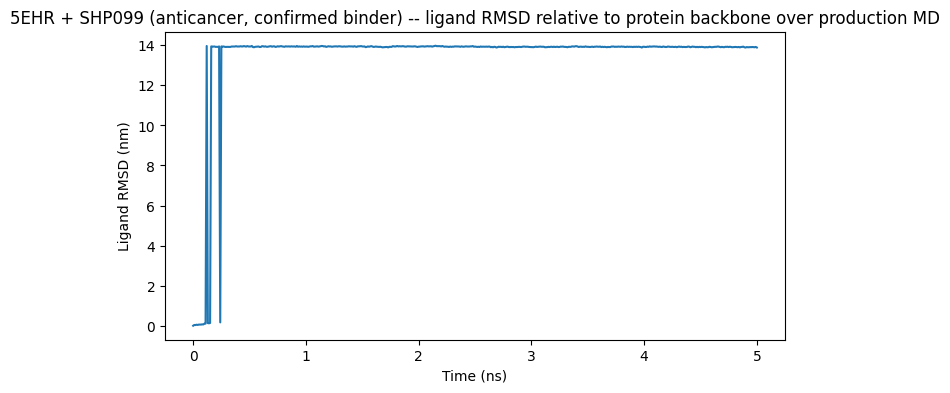

In [23]:
import matplotlib.pyplot as plt

time_ns, rmsd_nm = [], []
with open("results/ligand_rmsd.xvg") as f:
    for line in f:
        if line.startswith(("#", "@")): continue
        t, r = line.split()
        time_ns.append(float(t)); rmsd_nm.append(float(r))

plt.figure(figsize=(8,4))
plt.plot(time_ns, rmsd_nm)
plt.xlabel("Time (ns)"); plt.ylabel("Ligand RMSD (nm)")
plt.title("5EHR + SHP099 (anticancer, confirmed binder) -- ligand RMSD relative to protein backbone over production MD")
plt.savefig("results/ligand_rmsd_vs_time.png", dpi=150)
plt.show()


## Visualize the docked pose

Two views: (1) an interactive 3D structure -- protein cartoon + top-ranked ligand pose + the
fpocket-detected binding box used for docking -- via `py3Dmol`. This is a live JS widget: it renders
when the notebook is actually run (Kaggle output, local Jupyter) but NOT in GitHub's static `.ipynb`
preview. (2) A static binding-affinity bar chart across all sampled poses, which renders everywhere,
including GitHub.

In [24]:
import sys
!{sys.executable} -m pip install -q py3Dmol

import py3Dmol

# convert the top docked pose (model 1 of the multi-pose PDBQT) to plain PDB for 3Dmol
top_pose_pdb = f"results/docking/{PDB_ID}_{CID}_top_pose.pdb"
!obabel {pose_path} -O {top_pose_pdb} -f 1 -l 1

with open(clean_path) as f:
    protein_block = f.read()
with open(top_pose_pdb) as f:
    ligand_block = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(protein_block, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "spectrum"}})
view.addModel(ligand_block, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon"}})

# fpocket-detected binding box used for docking (Step 3)
view.addBox({
    "center": {"x": float(center[0]), "y": float(center[1]), "z": float(center[2])},
    "dimensions": {"w": float(size[0]), "h": float(size[1]), "d": float(size[2])},
    "color": "yellow", "opacity": 0.2,
})
view.zoomTo({"model": 1})
view.show()


1 molecule converted


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

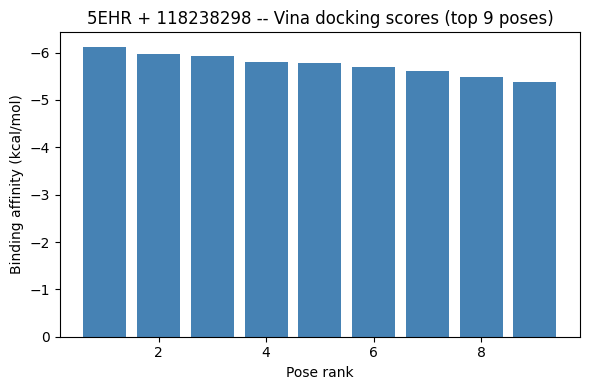

In [25]:
import matplotlib.pyplot as plt

# re-pull all sampled poses' affinities from the still-live Vina object (v) from the docking step
energies = v.energies(n_poses=9)
affinities = [row[0] for row in energies]

plt.figure(figsize=(6, 4))
plt.bar(range(1, len(affinities) + 1), affinities, color="steelblue")
plt.xlabel("Pose rank")
plt.ylabel("Binding affinity (kcal/mol)")
plt.title(f"{PDB_ID} + {CID} -- Vina docking scores (top {len(affinities)} poses)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/docking/vina_scores_barplot.png", dpi=150)
plt.show()
